# Práctica 4b · Comparativa de OCR: clásicos frente a VLM

**Ejecutar todo** compara tres modelos sobre los 217 recortes de matrícula de `datos/matriculas_recortadas/ocr_dataset.csv`:

| Tipo | Modelo |
|---|---|
| OCR clásico | EasyOCR |
| OCR clásico | Tesseract 5 |
| VLM | SmolVLM-500M-Instruct |

Mismas imágenes, misma normalización de la salida y una inferencia de calentamiento antes de cronometrar.
Métricas: **acierto exacto** (matrícula completa), **acierto por carácter** (`1 − Levenshtein / longitud`) y **tiempo medio** por recorte.

In [1]:
import os, sys
from pathlib import Path
# Si el kernel no se abrió con "conda activate VC_P4", las DLL de SSL no se encuentran y fallan las descargas
os.environ["PATH"] = os.pathsep.join([sys.prefix, str(Path(sys.prefix) / "Library" / "bin"), os.environ["PATH"]])

import csv, platform, time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from tqdm.auto import tqdm

AQUI = Path.cwd()                                   # carpeta P4b
RECORTES = AQUI.parent / "datos" / "matriculas_recortadas"
SALIDA = AQUI / "resultados_ocr"
SALIDA.mkdir(exist_ok=True)
TESSERACT = r"C:/Program Files/Tesseract-OCR/tesseract.exe"
MODELOS = ["easyocr", "tesseract", "smolvlm"]       # quita alguno para ir más rápido

E:\conda\envs\VC_P4\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Equipo de pruebas

In [2]:
import subprocess
cpu = subprocess.run(["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"],
                     capture_output=True, text=True).stdout.strip() or platform.processor()
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"
print(f"CPU: {cpu}\nGPU: {gpu}\nPyTorch {torch.__version__} | Python {platform.python_version()}")

CPU: Intel(R) Core(TM) i5-10400F CPU @ 2.90GHz
GPU: NVIDIA GeForce RTX 3050
PyTorch 2.8.0+cu126 | Python 3.9.5


## Datos y métricas

In [3]:
import re

ALFABETO = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
# Formato actual (4 dígitos + 3 consonantes) y provincial antiguo (1-2 letras + 4 dígitos + 1-2 letras)
PATRON_ACTUAL = re.compile(r"\d{4}[BCDFGHJKLMNPRSTVWXYZ]{3}")
PATRON_PROVINCIAL = re.compile(r"[A-Z]{1,3}\d{4}[A-Z]{1,2}")


def normalizar(texto):
    """Mayúsculas, solo alfanuméricos y, si aparece, el fragmento con formato de matrícula."""
    t = re.sub(r"[^0-9A-Z]", "", texto.upper())
    m = PATRON_ACTUAL.search(t) or PATRON_PROVINCIAL.search(t)
    if m:
        return m.group(0)
    return t[1:] if t.startswith("E") and len(t) == 8 else t  # 'E' de la franja azul



def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def leer(ruta):
    return cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_COLOR)


with open(RECORTES / "ocr_dataset.csv", encoding="utf-8-sig") as f:
    muestras = list(csv.DictReader(f, delimiter=";"))
imagenes = [leer(RECORTES / m["ruta_recorte"]) for m in muestras]
print(f"{len(muestras)} recortes | fáciles: {sum(m['dificultad'] == 'facil' for m in muestras)}"
      f" | difíciles: {sum(m['dificultad'] == 'dificil' for m in muestras)}")

217 recortes | fáciles: 174 | difíciles: 43


## Modelos

Cada función `cargar_*` devuelve otra función `imagen BGR -> texto`.

- **EasyOCR**: alfabeto limitado a `0-9A-Z`.
- **Tesseract**: gris → altura 96 px → Otsu → borde blanco, `--psm 7` (una sola línea).
- **SmolVLM-500M**: el SmolVLM-Instruct del cuaderno de ejemplo (2B) es demasiado pesado para la GPU de pruebas. Prompt corto y decodificación greedy.

In [4]:
def cargar_easyocr():
    import easyocr
    reader = easyocr.Reader(["es"], gpu=True, verbose=False)
    return lambda img: " ".join(reader.readtext(img, allowlist=ALFABETO, detail=0, paragraph=True))


def cargar_tesseract():
    import pytesseract
    pytesseract.pytesseract.tesseract_cmd = TESSERACT
    cfg = f"--psm 7 -c tessedit_char_whitelist={ALFABETO}"

    def ocr(img):
        gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        escala = 96 / gris.shape[0]
        gris = cv2.resize(gris, None, fx=escala, fy=escala, interpolation=cv2.INTER_CUBIC)
        _, bin_ = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        bin_ = cv2.copyMakeBorder(bin_, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=255)
        return pytesseract.image_to_string(bin_, lang="eng", config=cfg)
    return ocr


def cargar_smolvlm(nombre="HuggingFaceTB/SmolVLM-500M-Instruct"):
    from PIL import Image
    from transformers import AutoModelForImageTextToText, AutoProcessor
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    processor = AutoProcessor.from_pretrained(nombre)
    model = AutoModelForImageTextToText.from_pretrained(
        nombre, dtype=torch.bfloat16 if dev == "cuda" else torch.float32,
        _attn_implementation="eager").to(dev).eval()
    mensajes = [{"role": "user", "content": [
        {"type": "image"},
        {"type": "text", "text": "Read the license plate in the image. Answer only with its characters."}]}]
    prompt = processor.apply_chat_template(mensajes, add_generation_prompt=True)

    def ocr(img):
        pil = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        inputs = processor(text=prompt, images=[pil], return_tensors="pt").to(dev)
        with torch.no_grad():
            ids = model.generate(**inputs, max_new_tokens=16, do_sample=False)
        return processor.batch_decode(ids[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]
    return ocr


CARGADORES = {"easyocr": cargar_easyocr, "tesseract": cargar_tesseract, "smolvlm": cargar_smolvlm}

## Evaluación (≈8 min en total, casi todo SmolVLM)

In [5]:
filas, resumen = [], []
for nombre in MODELOS:
    ocr = CARGADORES[nombre]()
    ocr(imagenes[0])  # calentamiento: no cuenta en los tiempos
    for m, img in tqdm(list(zip(muestras, imagenes)), desc=nombre):
        t0 = time.perf_counter()
        bruto = ocr(img)
        dt = time.perf_counter() - t0
        pred, real = normalizar(bruto), m["matricula"]
        d = levenshtein(pred, real)
        filas.append({"modelo": nombre, "recorte": m["ruta_recorte"], "dificultad": m["dificultad"],
                      "real": real, "bruto": bruto.strip().replace("\n", " "), "prediccion": pred,
                      "exacto": int(pred == real), "distancia": d, "tiempo_ms": round(dt * 1000, 1)})
    sub = [f for f in filas if f["modelo"] == nombre]
    resumen.append({"modelo": nombre, "n": len(sub),
                    "acierto_exacto": round(sum(f["exacto"] for f in sub) / len(sub), 4),
                    "acierto_caracter": round(1 - sum(min(f["distancia"], len(f["real"])) for f in sub)
                                              / sum(len(f["real"]) for f in sub), 4),
                    "tiempo_medio_ms": round(sum(f["tiempo_ms"] for f in sub) / len(sub), 1)})
    del ocr
    torch.cuda.empty_cache()

for archivo, datos in (("predicciones.csv", filas), ("resumen.csv", resumen)):
    with open(SALIDA / archivo, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(datos[0]))
        w.writeheader()
        w.writerows(datos)

easyocr:   0%|          | 0/217 [00:00<?, ?it/s]

easyocr:   1%|          | 2/217 [00:00<00:12, 16.71it/s]

easyocr:   2%|▏         | 4/217 [00:00<00:18, 11.65it/s]

easyocr:   3%|▎         | 6/217 [00:00<00:18, 11.13it/s]

easyocr:   4%|▎         | 8/217 [00:00<00:18, 11.32it/s]

easyocr:   5%|▍         | 10/217 [00:00<00:19, 10.77it/s]

... (518 outputs left out)

smolvlm:  99%|█████████▉| 215/217 [05:05<00:02,  1.36s/it]

smolvlm: 100%|█████████▉| 216/217 [05:06<00:01,  1.29s/it]

smolvlm: 100%|██████████| 217/217 [05:08<00:00,  1.46s/it]

smolvlm: 100%|██████████| 217/217 [05:08<00:00,  1.42s/it]

## Resultados

In [6]:
tabla = "| Modelo | Acierto exacto | Acierto por carácter | Tiempo medio | Fáciles | Difíciles |\n|---|---|---|---|---|---|\n"
for r in resumen:
    por_dif = []
    for dif in ("facil", "dificil"):
        sub = [f for f in filas if f["modelo"] == r["modelo"] and f["dificultad"] == dif]
        por_dif.append(f"{100 * sum(f['exacto'] for f in sub) / len(sub):.1f} %")
    tabla += (f"| {r['modelo']} | {100 * r['acierto_exacto']:.1f} % | {100 * r['acierto_caracter']:.1f} % "
              f"| {r['tiempo_medio_ms']:.0f} ms | {por_dif[0]} | {por_dif[1]} |\n")
display(Markdown(tabla))

| Modelo | Acierto exacto | Acierto por carácter | Tiempo medio | Fáciles | Difíciles |
|---|---|---|---|---|---|
| easyocr | 70.5 % | 88.3 % | 72 ms | 79.9 % | 32.6 % |
| tesseract | 25.8 % | 39.2 % | 152 ms | 29.3 % | 11.6 % |
| smolvlm | 85.7 % | 94.0 % | 1421 ms | 91.4 % | 62.8 % |


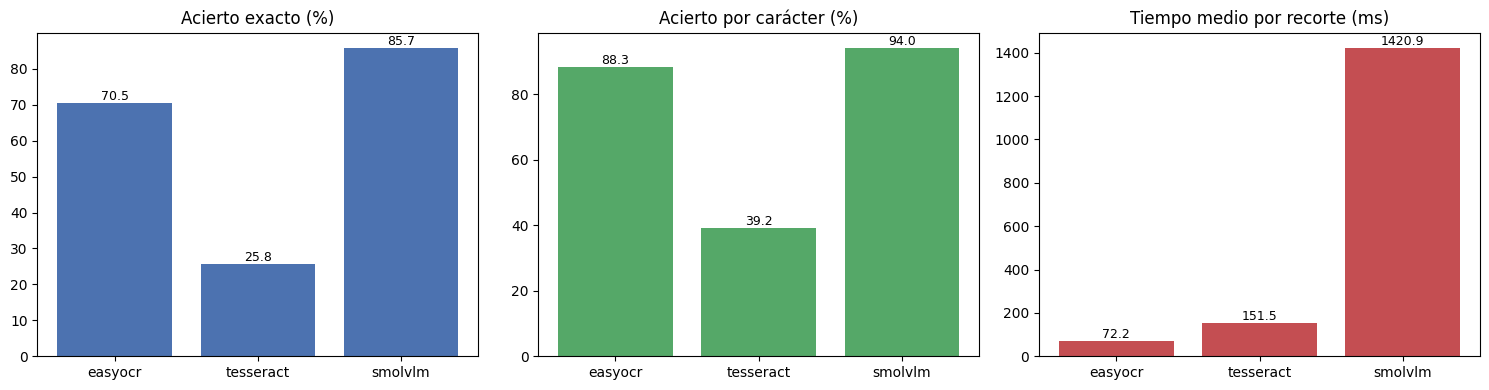

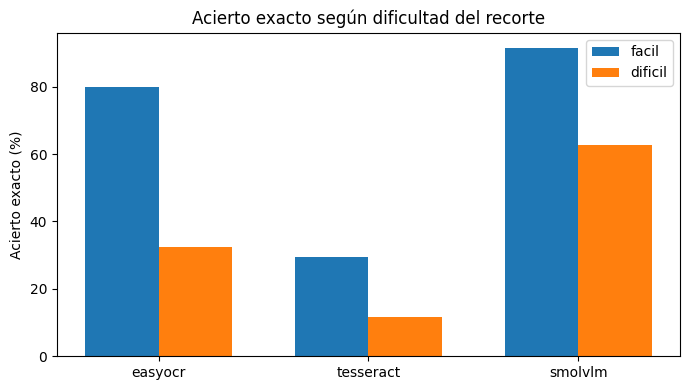

In [7]:
nombres = [r["modelo"] for r in resumen]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].bar(nombres, [r["acierto_exacto"] * 100 for r in resumen], color="#4C72B0")
axs[0].set_title("Acierto exacto (%)")
axs[1].bar(nombres, [r["acierto_caracter"] * 100 for r in resumen], color="#55A868")
axs[1].set_title("Acierto por carácter (%)")
axs[2].bar(nombres, [r["tiempo_medio_ms"] for r in resumen], color="#C44E52")
axs[2].set_title("Tiempo medio por recorte (ms)")
for ax in axs:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(SALIDA / "comparativa_ocr.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ancho = 0.35
for k, dif in enumerate(("facil", "dificil")):
    valores = []
    for m in nombres:
        sub = [f for f in filas if f["modelo"] == m and f["dificultad"] == dif]
        valores.append(100 * sum(f["exacto"] for f in sub) / len(sub))
    ax.bar(np.arange(len(nombres)) + k * ancho, valores, ancho, label=dif)
ax.set_xticks(np.arange(len(nombres)) + ancho / 2)
ax.set_xticklabels(nombres)
ax.set_ylabel("Acierto exacto (%)")
ax.set_title("Acierto exacto según dificultad del recorte")
ax.legend()
fig.tight_layout()
fig.savefig(SALIDA / "acierto_por_dificultad.png", dpi=120)
plt.show()

### Ejemplos de recortes difíciles y lo que lee cada modelo

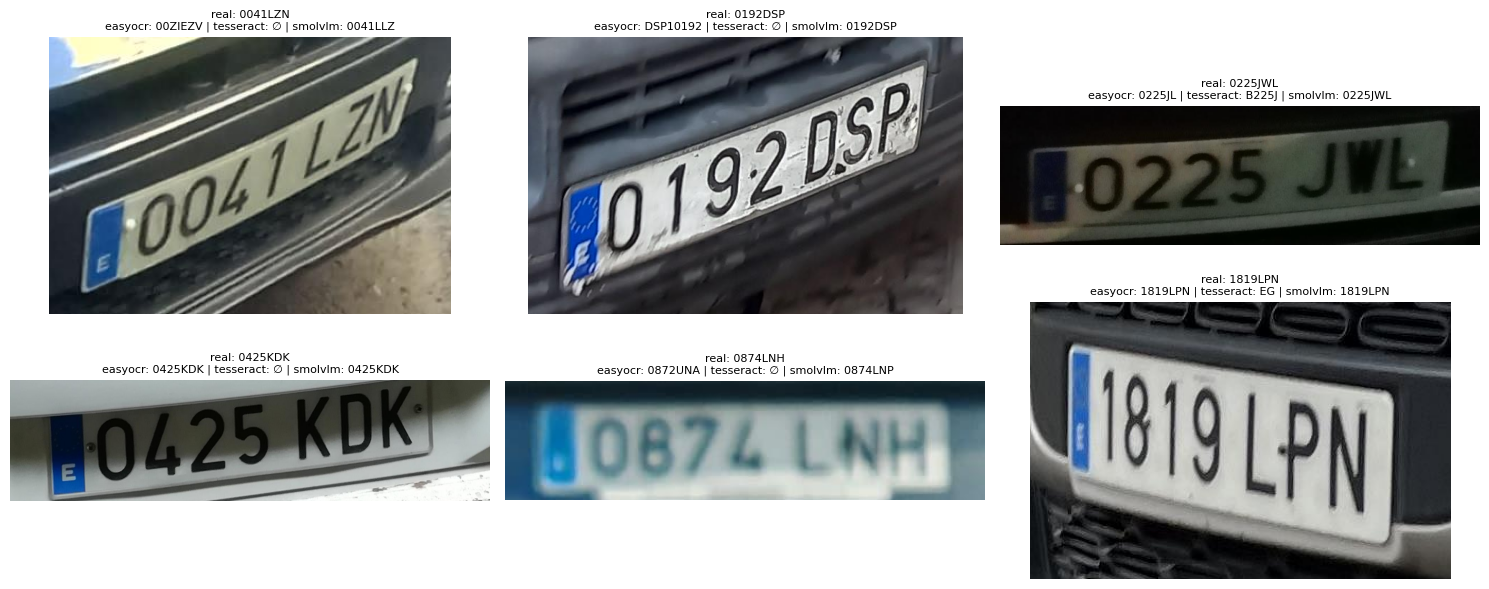

In [8]:
dificiles = [m for m in muestras if m["dificultad"] == "dificil"][:6]
pred = {(f["modelo"], f["recorte"]): f["prediccion"] for f in filas}
fig, axs = plt.subplots(2, 3, figsize=(15, 6))
for ax, m in zip(axs.flat, dificiles):
    ax.imshow(cv2.cvtColor(leer(RECORTES / m["ruta_recorte"]), cv2.COLOR_BGR2RGB))
    lecturas = " | ".join(f"{n}: {pred[(n, m['ruta_recorte'])] or '∅'}" for n in nombres)
    ax.set_title(f"real: {m['matricula']}\n{lecturas}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusiones

- **El VLM es el más preciso**, sobre todo en recortes difíciles (pequeños, borrosos o inclinados): su modelo de lenguaje reconstruye caracteres degradados.
- **Pero es unas 20 veces más lento que EasyOCR** (≈1,5 s frente a ≈70 ms por recorte): no es viable ejecutarlo en cada fotograma de un vídeo de 25 fps.
- **EasyOCR es el mejor compromiso para el prototipo de vídeo**: rápido y, combinado con la votación por vehículo, suficientemente fiable. Por eso es el OCR integrado en P4.
- **Tesseract no sirve para matrículas** sin un preprocesado específico: está pensado para documentos y a menudo devuelve la cadena vacía.
- Mejora posible: un esquema híbrido, con EasyOCR en cada fotograma y SmolVLM una sola vez por vehículo sobre su recorte más nítido.